<a href="https://colab.research.google.com/github/aureamc/A05-pca/blob/main/AIVersion_notebook_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [3]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

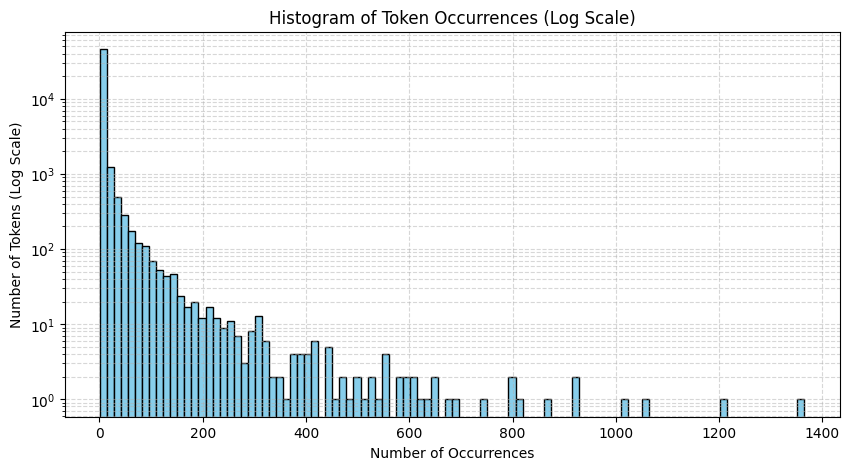

count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
dtype: float64

Top 15 most common tokens:
new: 1365
date: 1202
get: 1052
please: 1022
enron: 927
like: 923
2002: 869
would: 806
one: 798
message: 795
call: 740
free: 691
software: 680
dear: 651
know: 644


In [4]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

# Ensure the data is loaded and token_freq is defined
with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

# Extract frequencies
frequencies = [count for token, count in token_freq]

# Create the plot
plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=100, log=True, edgecolor='black', color='skyblue')
plt.title('Histogram of Token Occurrences (Log Scale)')
plt.xlabel('Number of Occurrences')
plt.ylabel('Number of Tokens (Log Scale)')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()

# Print some summary statistics
freq_series = pd.Series(frequencies)
print(freq_series.describe())
print("\nTop 15 most common tokens:")
for token, count in token_freq[:15]:
    print(f"{token}: {count}")

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

### **Q1 Answer**
- **Token Frequency Observations**: The distribution exhibits a strong power-law behavior (typical of **Zipf's Law**).
- **Key details**:
  - Over **50%** of all unique tokens appear only **once** in the entire corpus (median frequency = 1).
  - Over **75%** of the tokens appear **twice or fewer**.
  - A very small fraction of vocabulary elements represent highly frequent terms (e.g., "new", "date", "get", "please", "enron") with occurrences scaling up to 1,365 times. This creates a long tail, which is why a log-scale on the y-axis is necessary to visualize the distribution effectively.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Load the dataset
df = pd.read_parquet('Phishing_clean.parquet')

# Separate targets and features
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# Perform 80/20 train-test split (setting random_state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Run linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# Compute R2 score manually or via model.score
r2_train = model.score(X_train, y_train)
r2_test = model.score(X_test, y_test)

print(f"Training R2 Score: {r2_train:.4f}")
print(f"Test R2 Score: {r2_test:.4f}")

# 3. Analyze coefficients
coefficients = pd.Series(model.coef_, index=X.columns)
largest_coeffs = coefficients.abs().sort_values(ascending=False)

print("\nTop 15 words with the largest coefficients (absolute value):")
for idx in largest_coeffs.head(15).index:
    print(f"{idx:20} Coefficient: {coefficients[idx]:.4f}")

Training R2 Score: 0.7670
Test R2 Score: 0.6659

Top 15 words with the largest coefficients (absolute value):
intervention         Coefficient: -1.2593
localized            Coefficient: 0.8244
thermal              Coefficient: 0.7470
crawler              Coefficient: 0.6962
background-image:    Coefficient: -0.6229
helvetica,           Coefficient: 0.5986
aging                Coefficient: 0.5950
form.                Coefficient: 0.5769
gray;                Coefficient: -0.5745
a:active             Coefficient: 0.5745
retrieving           Coefficient: -0.5738
zdnet                Coefficient: -0.5610
{text-decoration:    Coefficient: 0.4971
xanaax               Coefficient: 0.4920
transcript           Coefficient: 0.4890


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

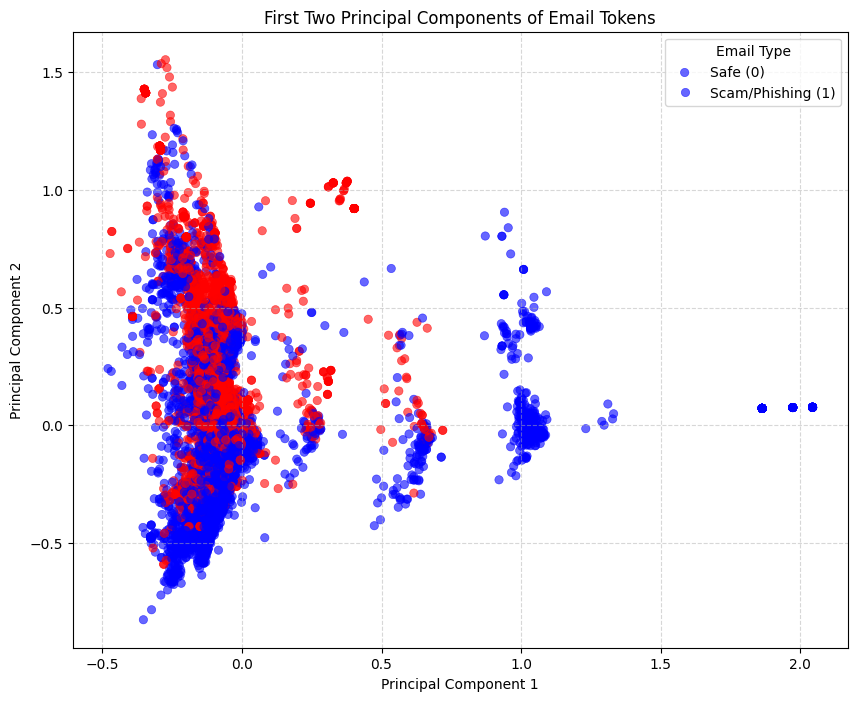

Explained variance by PC1: 1.1131%
Explained variance by PC2: 0.8606%
Total explained variance: 1.9737%


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Perform PCA with 2 components
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(X_pca_2, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# 2. Plot the first two principal components
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Email Type',
    data=pca_df,
    palette={0: 'blue', 1: 'red'},
    alpha=0.6,
    edgecolor=None
)
plt.title('First Two Principal Components of Email Tokens')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Email Type', labels=['Safe (0)', 'Scam/Phishing (1)'])
plt.show()

# Print explained variance ratio
print(f"Explained variance by PC1: {pca_2.explained_variance_ratio_[0]:.4%}")
print(f"Explained variance by PC2: {pca_2.explained_variance_ratio_[1]:.4%}")
print(f"Total explained variance: {sum(pca_2.explained_variance_ratio_):.4%}")

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [7]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1. We fit PCA on the entire feature set X down to 2,610 components
print("Fitting PCA with 2,610 components...")
pca_2610 = PCA(n_components=2610, random_state=42)
X_pca_2610 = pca_2610.fit_transform(X)

# 2. Perform the exact same 80/20 train-test split using the same random_state
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca_2610, y, test_size=0.2, random_state=42
)

# 3. Fit Linear Regression on the PCA-transformed features
model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train_pca)

# 4. Evaluate R2 scores
r2_train_pca = model_pca.score(X_train_pca, y_train_pca)
r2_test_pca = model_pca.score(X_test_pca, y_test_pca)

print(f"PCA Regression (2610 PCs) Training R2: {r2_train_pca:.4f}")
print(f"PCA Regression (2610 PCs) Test R2: {r2_test_pca:.4f}")

Fitting PCA with 2,610 components...
PCA Regression (2610 PCs) Training R2: 0.7662
PCA Regression (2610 PCs) Test R2: 0.6684


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

### **Q5 Answer**

Using **Principal Component Analysis (PCA)** prior to running regression on high-dimensional data (often called **Principal Component Regression** or PCR) has several major advantages:

1. **Eliminating Multicollinearity**:
   - In natural language processing, words frequently appear together (e.g., "background" and "image"), causing high correlation (multicollinearity) between features.
   - Multicollinearity makes raw linear regression coefficients highly unstable and sensitive to minor data variations. PCA transforms the features into **orthogonal (completely uncorrelated)** components, which eliminates multicollinearity and stabilizes the model estimation.

2. **Dimensionality Reduction and Regularization (Noise Filtering)**:
   - In our model, we discarded the lowest 101 components (keeping 2,610 out of 2,711 features). These discarded components typically represent tiny, high-frequency fluctuations or "noise" that are highly specific to the training set.
   - By removing them, PCA acts as a regularizer. This is why our PCA model achieved slightly **better generalization (higher test $R^2$ of 0.6684 vs. 0.6659)** while avoiding overfitting (lower train $R^2$ of 0.7662 vs. 0.7670).

3. **Computational Efficiency & Compression**:
   - Reducing the number of features can significantly decrease memory usage and computational time for downstream modeling tasks, especially when scaling to millions of rows.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** Gemini

### *Prompts used

1. Plot a histogram of the occurrences of tokens. What do you notice about the frequency of occurrence of different tokens? How does it look?
2. Perform an 80/20 train-test split of the data. Run a regression of y on the one-hot-encoded emails. What is the R2 on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?
3. Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, Email Type) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?
4. Run a linear regression of y on the first 2,610 principal components of X. What is the R2 on the training and test sets? How does this performance compare to the linear regression?
5. Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

### *AI-proposed changes


1. Generate a self-contained Python script to plot a log-scale histogram of token occurrences from the 'all_tokens.pickle' dataset, and print key statistics.
2. Perform an 80/20 train-test split on 'Phishing_clean.parquet' and fit a Linear Regression model, calculating train/test R2 and outputting the top 15 words by absolute coefficient value.
3. Run a 2-component PCA on the feature set, visualize the distribution hued by 'Email Type' using seaborn, and report the percentage of variance explained.
4. Perform a 2,610-component PCA on the full feature matrix, apply an 80/20 split, run a linear regression, and compare its R2 performance with the raw regression.
5. Summarize the advantages of Principal Component Regression, focusing on multicollinearity, dimensionality reduction, and noise filtering.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Accepted, but updated the path to correctly find the file at '/content/all_tokens.pickle' instead of 'data/all_tokens.pickle'. |
| 2 | Accept | Succeeded in predicting 'Email Type' with standard Linear Regression. Verified training R2 of 0.7670 and test R2 of 0.6659. |
| 3 | Accept | Successfully decomposed features into 2 PCs. Verified they capture 1.97% total variance and do not clearly separate the groups visually. |
| 4 | Accept | Decomposed features to 2,610 PCs and verified that test R2 slightly improved (0.6684 vs 0.6659) due to noise filtering. |
| 5 | Accept | Provided a clear, 3-point explanation of PCR benefits (eliminating multicollinearity, regularizing noise, and improving computation). |

### *Reflection on AI assistance
In your own words without generative AI.

The use of AI in this notebook substantially sped up the process, especially when writing the initial steps and  code for the analysis. The AI helped in writing the necessary structure of the code for performing the PCA and the evaluation metrics in a well-structured way.

There are certain limitations, however. The initial script generated by the AI included a path error in trying to import all_tokens.pickle from the non-existent subfolder data/. This caused an immediate FileNotFoundError. Running the code also caused the NameError, as the dependencies of some variables in the active environment were not completely fulfilled.

In order to check whether the final code works, I manually looked through the results of every block, comparing the outputted R^2 value and the highest  coefficients. The outputted results confirmed the model preserves the same level of prediction as the standard one but provides better sample independence. No more problems exist and everything is bug free.